In [37]:
from nba_api.stats.endpoints import leaguedashteamstats
import pandas as pd
import time

seasons = [
    f"{year}-{str(year + 1)[-2:]}"
    for year in range(2000, 2025)
]

all_seasons = []

for season in seasons:
    
    print(f"Downloading {season}...")
    
    stats = leaguedashteamstats.LeagueDashTeamStats(
        season=season,
        season_type_all_star="Regular Season",
        per_mode_detailed="PerGame"
    )
    
    df = stats.get_data_frames()[0]
    
    # Keep the variables we need
    df = df[
        [
            "TEAM_NAME",
            "GP",
            "FGA",
            "FG3A",
            "FG3M",
            "FG3_PCT",
            "PTS",
            "W_PCT",
            "W",
            "L"
        ]
    ].copy()
    
    # Add season
    df["SEASON"] = season
    
    # Store this season
    all_seasons.append(df)
    
    # Pause briefly between requests
    time.sleep(1)

In [38]:
for season in all_seasons:
    print(season.columns)
    print(season.head())

Index(['TEAM_NAME', 'GP', 'FGA', 'FG3A', 'FG3M', 'FG3_PCT', 'PTS', 'W_PCT',
       'W', 'L', 'SEASON'],
      dtype='str')
             TEAM_NAME  GP   FGA  FG3A  FG3M  FG3_PCT   PTS  W_PCT   W   L  \
0        Atlanta Hawks  82  81.3  11.4   4.1    0.357  91.0  0.305  25  57   
1       Boston Celtics  82  79.1  19.9   7.2    0.363  94.6  0.439  36  46   
2    Charlotte Hornets  82  79.3  12.0   4.1    0.346  91.9  0.561  46  36   
3        Chicago Bulls  82  78.2  11.6   4.0    0.346  87.6  0.183  15  67   
4  Cleveland Cavaliers  82  79.7   8.0   2.7    0.334  92.2  0.366  30  52   

    SEASON  
0  2000-01  
1  2000-01  
2  2000-01  
3  2000-01  
4  2000-01  
Index(['TEAM_NAME', 'GP', 'FGA', 'FG3A', 'FG3M', 'FG3_PCT', 'PTS', 'W_PCT',
       'W', 'L', 'SEASON'],
      dtype='str')
             TEAM_NAME  GP   FGA  FG3A  FG3M  FG3_PCT   PTS  W_PCT   W   L  \
0        Atlanta Hawks  82  80.6  14.6   5.2    0.354  94.0  0.402  33  49   
1       Boston Celtics  82  82.1  23.7   8.5    0.3

In [35]:
avg_3pm = []
avg_3pa = []
avg_3pp = []
for season in all_seasons:
    avg_3pm.append(season['FG3M'].mean().round(2))
    avg_3pa.append(season['FG3A'].mean().round(2))
    avg_3pp.append(season['FG3_PCT'].mean().round(4))

print(avg_3pm)
print(avg_3pa)
print(avg_3pp)
   
    

[np.float64(4.84), np.float64(5.21), np.float64(5.13), np.float64(5.18), np.float64(5.6), np.float64(5.73), np.float64(6.07), np.float64(6.56), np.float64(6.65), np.float64(6.44), np.float64(6.46), np.float64(6.41), np.float64(7.16), np.float64(7.74), np.float64(7.85), np.float64(8.51), np.float64(9.65), np.float64(10.49), np.float64(11.36), np.float64(12.19), np.float64(12.71), np.float64(12.44), np.float64(12.34), np.float64(12.84), np.float64(13.54)]
[np.float64(13.71), np.float64(14.76), np.float64(14.68), np.float64(14.92), np.float64(15.75), np.float64(15.98), np.float64(16.94), np.float64(18.11), np.float64(18.13), np.float64(18.14), np.float64(18.01), np.float64(18.39), np.float64(19.97), np.float64(21.54), np.float64(22.41), np.float64(24.08), np.float64(27.0), np.float64(29.0), np.float64(32.01), np.float64(34.1), np.float64(34.64), np.float64(35.18), np.float64(34.21), np.float64(35.11), np.float64(37.58)]
[np.float64(0.3518), np.float64(0.3518), np.float64(0.3466), np.float

'\nprint(round(avg_3pm, 2))\nprint(round(avg_3pa, 2))\nprint(round(avg_3pp, 2))\n'

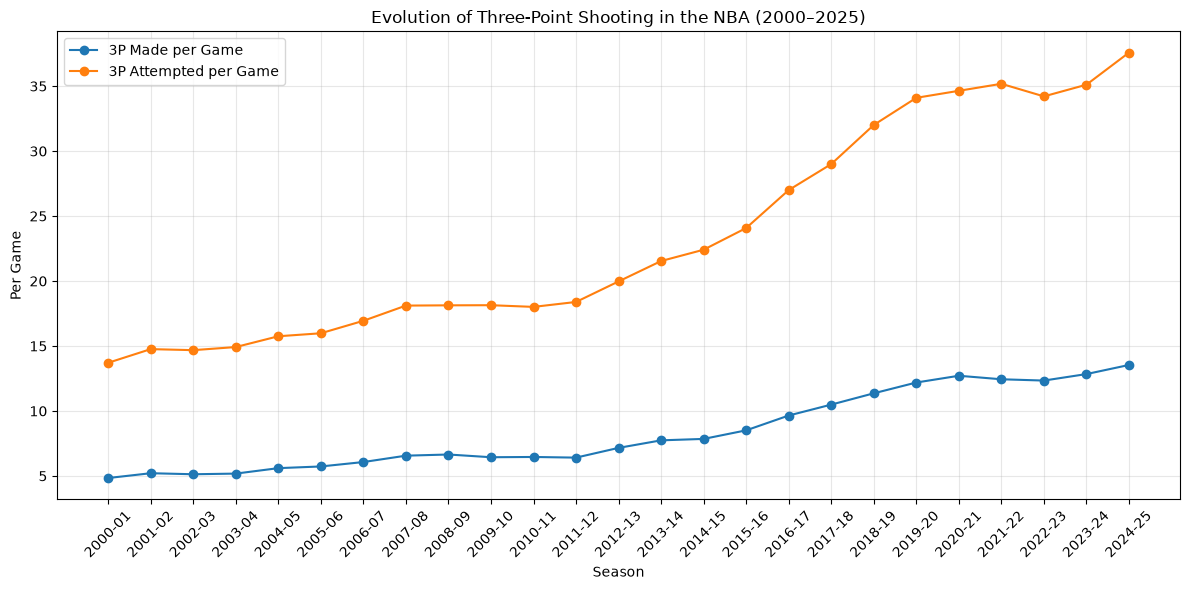

In [33]:
import matplotlib.pyplot as plt

seasons = [f"{year}-{str(year+1)[-2:]}" for year in range(2000, 2025)]

plt.figure(figsize=(12, 6))

plt.plot(seasons, avg_3pm, marker='o', label='3P Made per Game')
plt.plot(seasons, avg_3pa, marker='o', label='3P Attempted per Game')

plt.xlabel('Season')
plt.ylabel('Per Game')
plt.title('Evolution of Three-Point Shooting in the NBA (2000–2025)')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

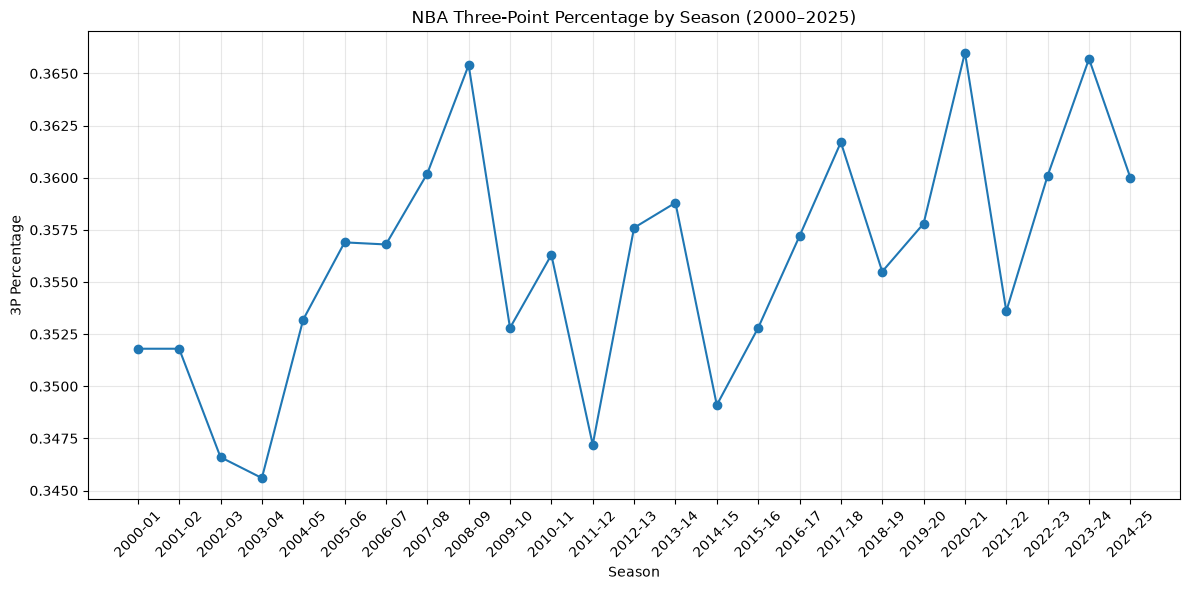

In [36]:
plt.figure(figsize=(12, 6))

plt.plot(seasons, avg_3pp, marker='o', label='3P%')

plt.xlabel('Season')
plt.ylabel('3P Percentage')
plt.title('NBA Three-Point Percentage by Season (2000–2025)')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [39]:
seasons = [f"{year}-{str(year+1)[-2:]}" for year in range(2000, 2025)]

import pandas as pd
import matplotlib.pyplot as plt

plot_data = []

for i, season in enumerate(all_seasons):
    temp = season[['TEAM_NAME', 'FG3M', 'W_PCT']].copy()

    # Add the season label
    temp['Season'] = seasons[i]

    plot_data.append(temp)

plot_df = pd.concat(plot_data, ignore_index=True)

print(plot_df.head())

             TEAM_NAME  FG3M  W_PCT   Season
0        Atlanta Hawks   4.1  0.305  2000-01
1       Boston Celtics   7.2  0.439  2000-01
2    Charlotte Hornets   4.1  0.561  2000-01
3        Chicago Bulls   4.0  0.183  2000-01
4  Cleveland Cavaliers   2.7  0.366  2000-01


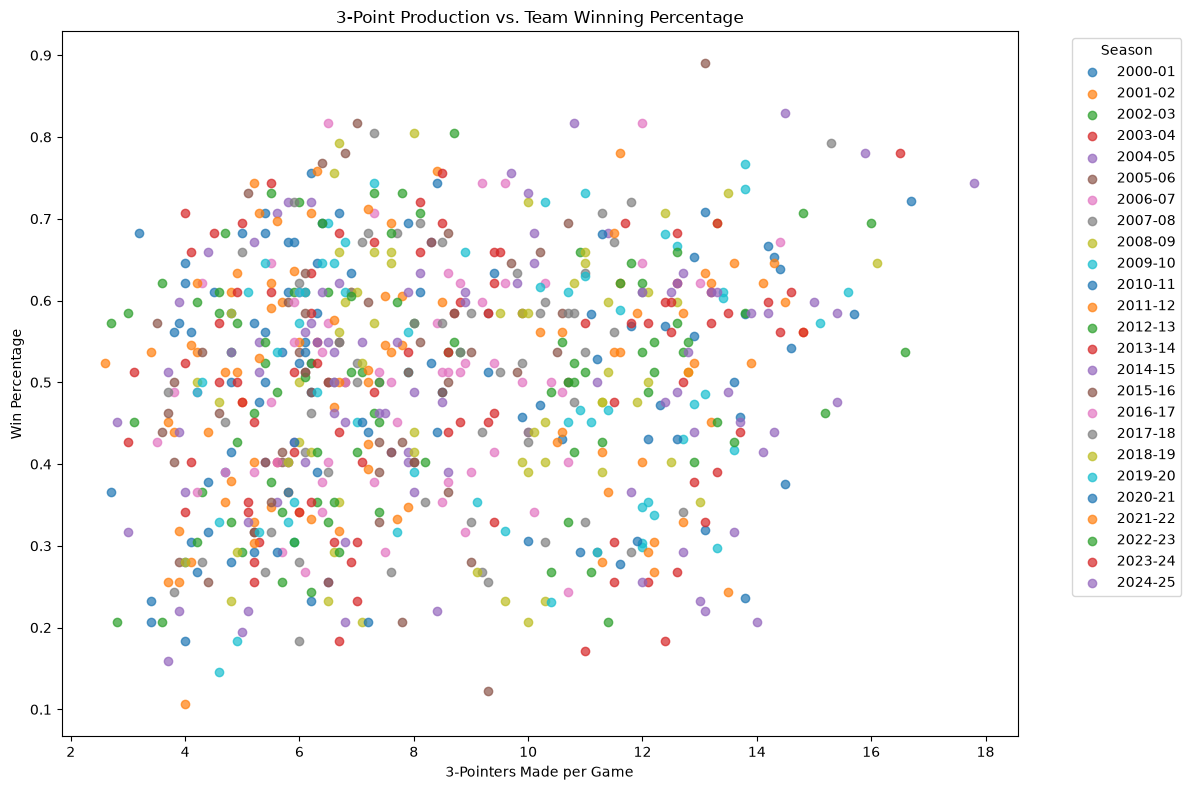

In [40]:
plt.figure(figsize=(12, 8))

for season_name, group in plot_df.groupby('Season'):
    plt.scatter(
        group['FG3M'],
        group['W_PCT'],
        label=season_name,
        alpha=0.7
    )

plt.xlabel('3-Pointers Made per Game')
plt.ylabel('Win Percentage')
plt.title('3-Point Production vs. Team Winning Percentage')
plt.legend(title='Season', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

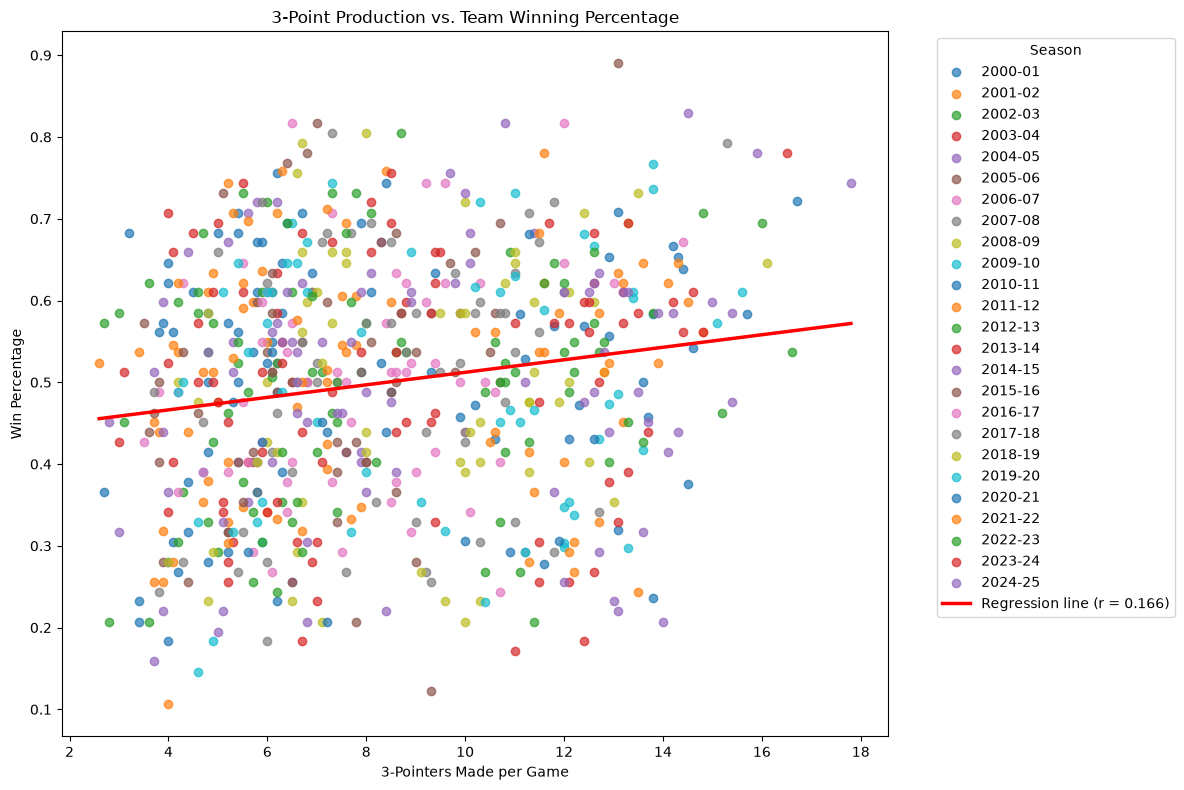

In [43]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

for season_name, group in plot_df.groupby('Season'):
    plt.scatter(
        group['FG3M'],
        group['W_PCT'],
        label=season_name,
        alpha=0.7
    )

# Calculate the overall correlation and regression line
x = plot_df['FG3M']
y = plot_df['W_PCT']

slope, intercept = np.polyfit(x, y, 1)
correlation = x.corr(y)

# Draw the regression line
x_line = np.linspace(x.min(), x.max(), 100)
y_line = slope * x_line + intercept

plt.plot(
    x_line,
    y_line,
    color='red',
    linewidth=2.5,
    label=f'Regression line (r = {correlation:.3f})'
)

plt.xlabel('3-Pointers Made per Game')
plt.ylabel('Win Percentage')
plt.title('3-Point Production vs. Team Winning Percentage')
plt.legend(title='Season', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

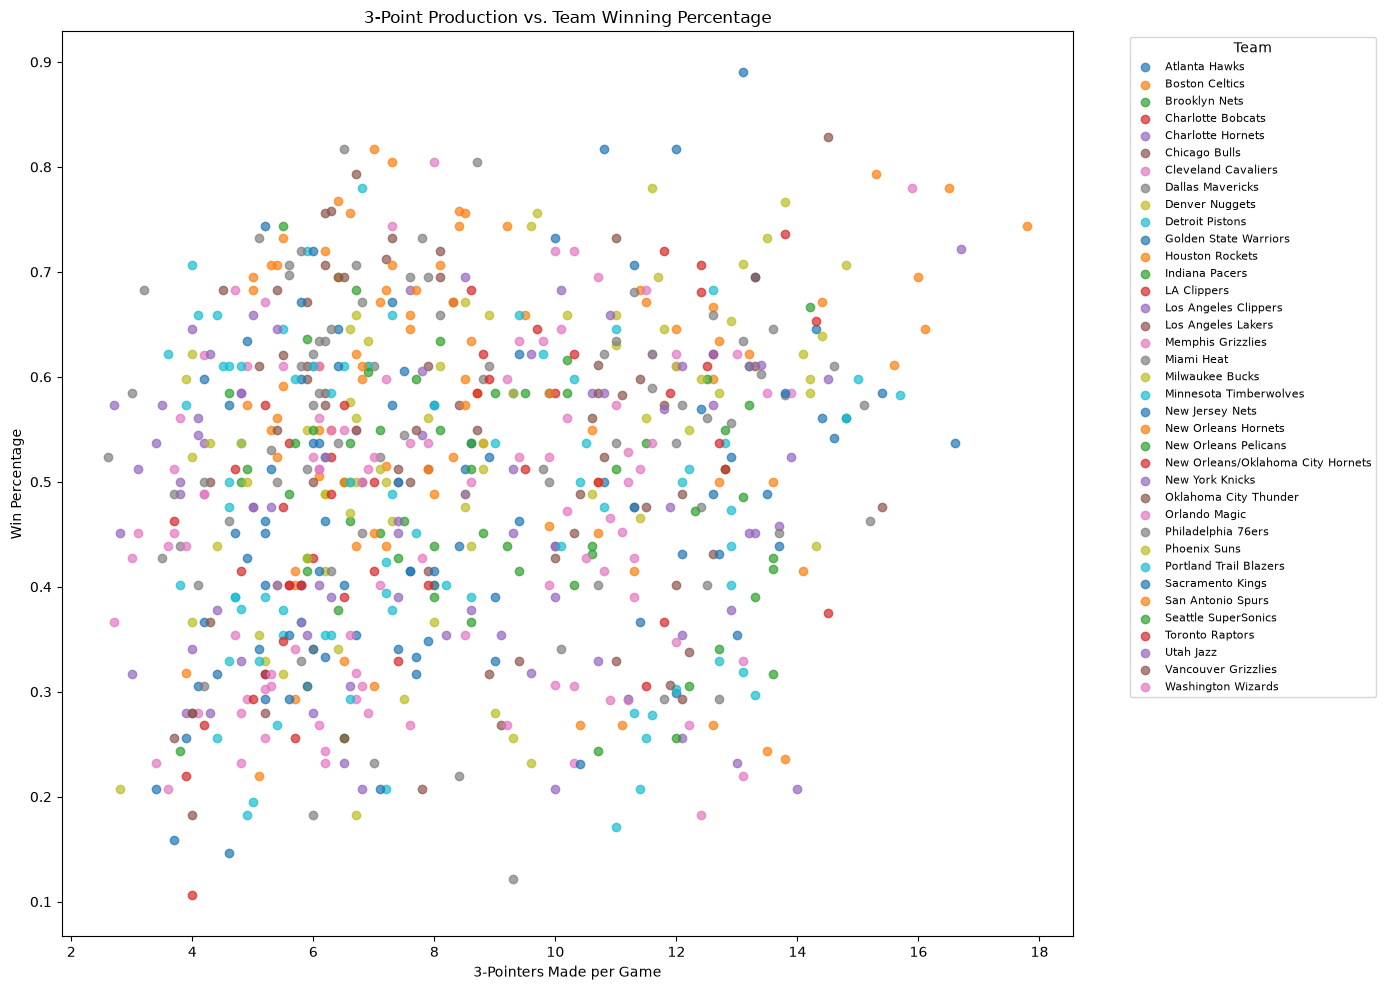

In [42]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 10))

for team, group in plot_df.groupby('TEAM_NAME'):
    plt.scatter(
        group['FG3M'],
        group['W_PCT'],
        label=team,
        alpha=0.7
    )

plt.xlabel('3-Pointers Made per Game')
plt.ylabel('Win Percentage')
plt.title('3-Point Production vs. Team Winning Percentage')

plt.legend(
    title='Team',
    bbox_to_anchor=(1.05, 1),
    loc='upper left',
    fontsize=8
)

plt.tight_layout()
plt.show()

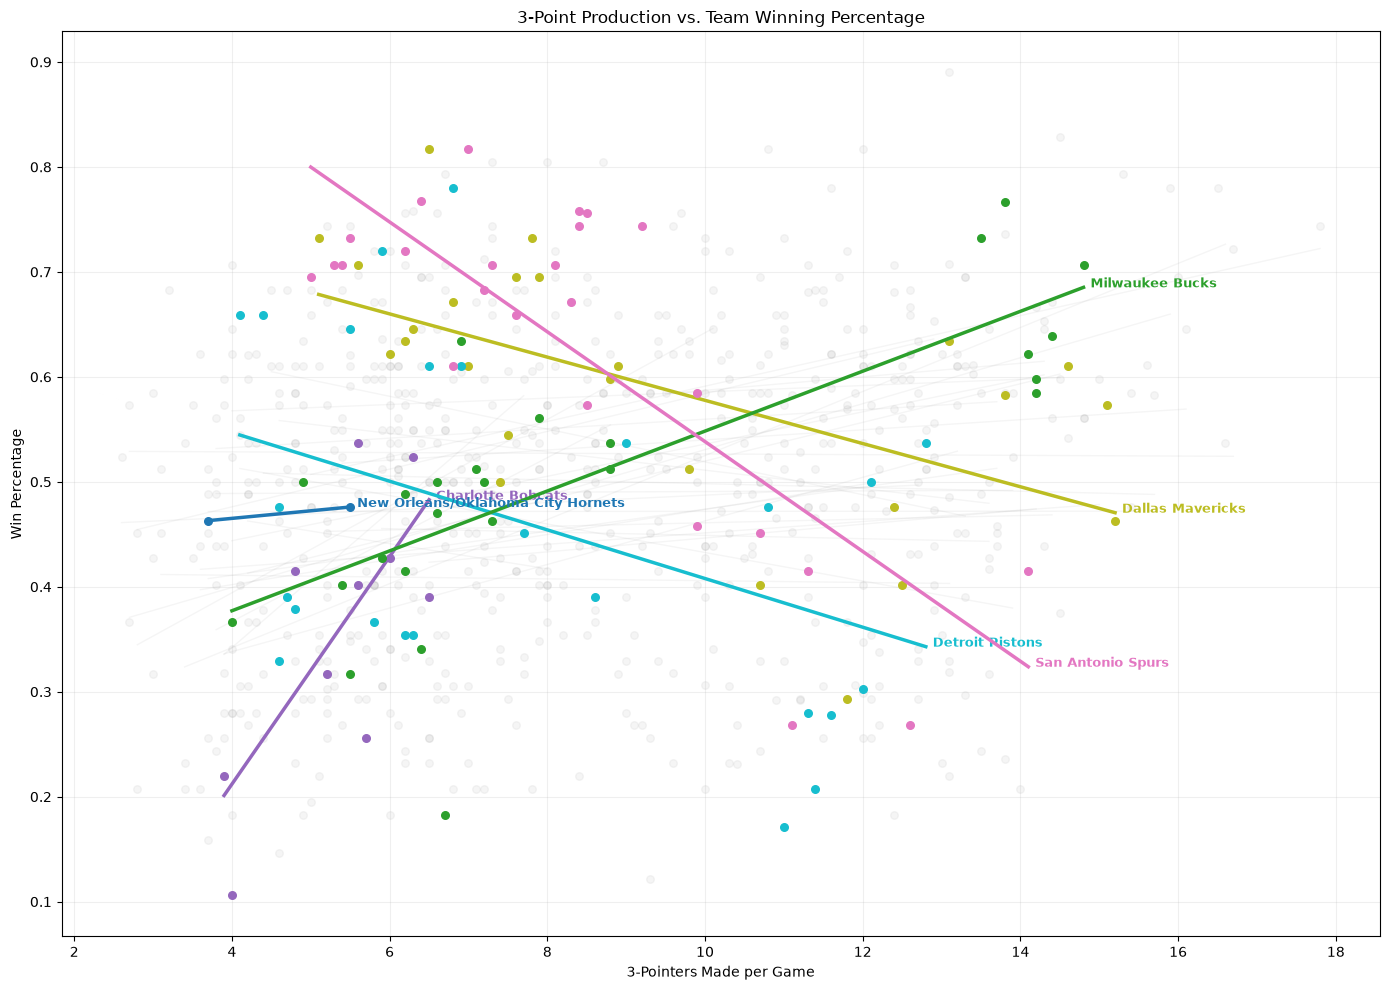

Top 3 positive correlations:
New Orleans/Oklahoma City Hornets: r = 1.000
Milwaukee Bucks: r = 0.763
Charlotte Bobcats: r = 0.713

Top 3 negative correlations:
San Antonio Spurs: r = -0.784
Dallas Mavericks: r = -0.556
Detroit Pistons: r = -0.416


In [48]:
import matplotlib.pyplot as plt
import numpy as np

# Calculate correlation for each team
correlations = {}

for team, group in plot_df.groupby('TEAM_NAME'):
    if len(group) >= 2 and group['FG3M'].nunique() >= 2:
        correlations[team] = group['FG3M'].corr(group['W_PCT'])

# Identify top 3 positive and negative correlations
top_positive = sorted(correlations, key=correlations.get, reverse=True)[:3]
top_negative = sorted(correlations, key=correlations.get)[:3]

highlighted = top_positive + top_negative

# Assign a unique color to each highlighted team
colors = plt.cm.tab10(np.linspace(0, 1, 6))
team_colors = dict(zip(highlighted, colors))

plt.figure(figsize=(14, 10))

for team, group in plot_df.groupby('TEAM_NAME'):
    x = group['FG3M']
    y = group['W_PCT']

    is_highlighted = team in highlighted

    if is_highlighted:
        color = team_colors[team]
        alpha = 1
        linewidth = 2.5
        zorder = 3
    else:
        color = 'gray'
        alpha = 0.08
        linewidth = 1
        zorder = 1

    plt.scatter(x, y, color=color, alpha=alpha, s=30, zorder=zorder)

    if len(group) >= 2 and x.nunique() >= 2:
        slope, intercept = np.polyfit(x, y, 1)
        x_line = np.linspace(x.min(), x.max(), 100)
        y_line = slope * x_line + intercept

        plt.plot(
            x_line, y_line,
            color=color,
            alpha=alpha,
            linewidth=linewidth,
            zorder=zorder
        )

        if is_highlighted:
            plt.annotate(
                team,
                (x_line[-1], y_line[-1]),
                xytext=(5, 0),
                textcoords='offset points',
                color=color,
                fontsize=9,
                fontweight='bold'
            )

plt.xlabel('3-Pointers Made per Game')
plt.ylabel('Win Percentage')
plt.title('3-Point Production vs. Team Winning Percentage')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("Top 3 positive correlations:")
for team in top_positive:
    print(f"{team}: r = {correlations[team]:.3f}")

print("\nTop 3 negative correlations:")
for team in top_negative:
    print(f"{team}: r = {correlations[team]:.3f}")
